<h1 style="text-align: center;">Phase 2 — Dataset V2.0: Feature Engineering and Model Experimentation</h1>



### Purpose

This notebook marks the second phase of experimentation in our football match outcome prediction project. Following the limited predictive performance achieved with Dataset V1.0 and V1.2, the objective is to investigate whether a more comprehensive dataset can improve both overall accuracy and balanced recall across **Home Win, Draw, and Away Win**.

### Experimental Approach

The initial strategy is to construct **Dataset V2.0** by integrating all relevant database tables and extracting meaningful features available before each match, while carefully preventing data leakage. The resulting dataset will be evaluated using selected high-performing machine learning algorithms, followed by hyperparameter tuning and systematic feature elimination to assess the contribution of different features.

The final results will be compared against previous experiments to determine whether richer pre-match information provides meaningful predictive improvements. Regardless of the outcome, the findings, limitations, and conclusions will be documented to support an evidence-based final assessment of the project.

----

## Dataset V2.0 — Data Integration and Preparation

This section begins the reconstruction of Dataset V2.0 using the original European Soccer Database. All seven relational tables are loaded and inspected before integration to ensure their structure and dimensions are understood.

The `Match` table will serve as the base dataset, while the remaining tables will be joined through their corresponding relationships. The objective is to preserve one record per match, incorporate relevant pre-match information, and subsequently identify data leakage, missing values, and unnecessary features.

In [1]:
import pandas as pd 
import duckdb
import sqlite3

In [2]:
connection = sqlite3.connect("../Data/database.sqlite")

In [3]:
match_df = pd.read_sql("SELECT * FROM Match", connection)
match_df.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


In [4]:
team_df = pd.read_sql("SELECT * FROM Team", connection)
team_df.head()

,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,1,9987,673.0,KRC Genk,GEN
1,2,9993,675.0,Beerschot AC,BAC
2,3,10000,15005.0,SV Zulte-Waregem,ZUL
3,4,9994,2007.0,Sporting Lokeren,LOK
4,5,9984,1750.0,KSV Cercle Brugge,CEB


In [5]:
team_attributes_df = pd.read_sql("SELECT * FROM Team_Attributes", connection)
team_attributes_df.head()

,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22 00:00:00,60,Balanced,NaN,Little,50,Mixed,...,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19 00:00:00,52,Balanced,48.0,Normal,56,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10 00:00:00,47,Balanced,41.0,Normal,54,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22 00:00:00,70,Fast,NaN,Little,70,Long,...,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22 00:00:00,47,Balanced,NaN,Little,52,Mixed,...,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


In [6]:
player_df = pd.read_sql("SELECT * FROM Player", connection)
player_df.head()

,id,player_api_id,player_name,player_fifa_api_id,birthday,height,weight
0,1,505942,Aaron Appindangoye,218353,1992-02-29 00:00:00,182.88,187
1,2,155782,Aaron Cresswell,189615,1989-12-15 00:00:00,170.18,146
2,3,162549,Aaron Doran,186170,1991-05-13 00:00:00,170.18,163
3,4,30572,Aaron Galindo,140161,1982-05-08 00:00:00,182.88,198
4,5,23780,Aaron Hughes,17725,1979-11-08 00:00:00,182.88,154


In [7]:
player_attributes_df = pd.read_sql("SELECT * FROM Player_Attributes", connection)
player_attributes_df.head()

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,1,218353,505942,2016-02-18 00:00:00,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
1,2,218353,505942,2015-11-19 00:00:00,67.0,71.0,right,medium,medium,49.0,...,54.0,48.0,65.0,69.0,69.0,6.0,11.0,10.0,8.0,8.0
2,3,218353,505942,2015-09-21 00:00:00,62.0,66.0,right,medium,medium,49.0,...,54.0,48.0,65.0,66.0,69.0,6.0,11.0,10.0,8.0,8.0
3,4,218353,505942,2015-03-20 00:00:00,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0
4,5,218353,505942,2007-02-22 00:00:00,61.0,65.0,right,medium,medium,48.0,...,53.0,47.0,62.0,63.0,66.0,5.0,10.0,9.0,7.0,7.0


In [8]:
league_df = pd.read_sql("SELECT * FROM League", connection)
league_df.head()

,id,country_id,name
0,1,1,Belgium Jupiler League
1,1729,1729,England Premier League
2,4769,4769,France Ligue 1
3,7809,7809,Germany 1. Bundesliga
4,10257,10257,Italy Serie A


In [9]:
country_df = pd.read_sql("SELECT * FROM Country", connection)
country_df.head()

,id,name
0,1,Belgium
1,1729,England
2,4769,France
3,7809,Germany
4,10257,Italy


In [10]:
datasets = {
    "Match": match_df,
    "Team": team_df,
    "Team_Attributes": team_attributes_df,
    "Player": player_df,
    "Player_Attributes": player_attributes_df,
    "League": league_df,
    "Country": country_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Match: (25979, 115)
Team: (299, 5)
Team_Attributes: (1458, 25)
Player: (11060, 7)
Player_Attributes: (183978, 42)
League: (11, 3)
Country: (11, 2)


----

## Dataset V2.0 — Relational Data Integration

This section combines information from the original European Soccer Database, using the `Match` table as the foundation. The objective is to integrate relevant team, league, country, and historical attribute information while preserving one record per match and preventing data leakage.

### 1. Creating Home and Away Table Copies

Separate copies of the Team, Player, and Attribute tables are created with `home_` and `away_` prefixes. This allows us to distinguish between both sides during the joining process and avoid duplicate column names.

In [11]:
# Team
home_team_df = team_df.copy().add_prefix("home_")
away_team_df = team_df.copy().add_prefix("away_")

# Team Attributes
home_team_attributes_df = team_attributes_df.copy().add_prefix("home_")
away_team_attributes_df = team_attributes_df.copy().add_prefix("away_")

# Player
home_player_df = player_df.copy().add_prefix("home_")
away_player_df = player_df.copy().add_prefix("away_")

# Player Attributes
home_player_attributes_df = player_attributes_df.copy().add_prefix("home_")
away_player_attributes_df = player_attributes_df.copy().add_prefix("away_")

### 2. Joining Home and Away Team Information

The Home and Away Team tables are merged with the base `Match` dataset using their respective team API IDs. Left joins are used to preserve all matches while incorporating team information.

In [12]:
# Start with Match table
v2_df = match_df.copy()

# Join Home Team
v2_df = v2_df.merge(
    home_team_df.drop(columns=["home_id"]),
    on="home_team_api_id",
    how="left",
    validate="many_to_one"
)

# Join Away Team
v2_df = v2_df.merge(
    away_team_df.drop(columns=["away_id"]),
    on="away_team_api_id",
    how="left",
    validate="many_to_one"
)

print(v2_df.shape)
v2_df.head()

(25979, 121)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,GBA,BSH,BSD,BSA,home_team_fifa_api_id,home_team_long_name,home_team_short_name,away_team_fifa_api_id,away_team_long_name,away_team_short_name
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.73,3.40,4.20,673.0,KRC Genk,GEN,675.0,Beerschot AC,BAC
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.75,1.91,3.25,3.60,15005.0,SV Zulte-Waregem,ZUL,2007.0,Sporting Lokeren,LOK
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.30,3.20,2.75,1750.0,KSV Cercle Brugge,CEB,229.0,RSC Anderlecht,AND
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,5.50,1.44,3.75,6.50,674.0,KAA Gent,GEN,1747.0,RAEC Mons,MON
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.65,4.75,3.30,1.67,NaN,FCV Dender EH,DEN,232.0,Standard de Liège,STL


### 3. Integrating League and Country Information

League and Country tables are merged using their corresponding identifiers. This provides additional information about the competition and country associated with each match.

In [13]:
# Rename columns
league_data = league_df[["id", "name"]].rename(
    columns={"id": "league_id", "name": "league_name"}
)

country_data = country_df.rename(
    columns={"id": "country_id", "name": "country_name"}
)

# Join League
v2_df = v2_df.merge(
    league_data,
    on="league_id",
    how="left",
    validate="many_to_one"
)

# Join Country
v2_df = v2_df.merge(
    country_data,
    on="country_id",
    how="left",
    validate="many_to_one"
)

print(v2_df.shape)
v2_df.head()

(25979, 123)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,BSD,BSA,home_team_fifa_api_id,home_team_long_name,home_team_short_name,away_team_fifa_api_id,away_team_long_name,away_team_short_name,league_name,country_name
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,3.40,4.20,673.0,KRC Genk,GEN,675.0,Beerschot AC,BAC,Belgium Jupiler League,Belgium
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.25,3.60,15005.0,SV Zulte-Waregem,ZUL,2007.0,Sporting Lokeren,LOK,Belgium Jupiler League,Belgium
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,3.20,2.75,1750.0,KSV Cercle Brugge,CEB,229.0,RSC Anderlecht,AND,Belgium Jupiler League,Belgium
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,3.75,6.50,674.0,KAA Gent,GEN,1747.0,RAEC Mons,MON,Belgium Jupiler League,Belgium
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,3.30,1.67,NaN,FCV Dender EH,DEN,232.0,Standard de Liège,STL,Belgium Jupiler League,Belgium


### 4. Preparing Historical Team Attributes

Historical Team Attributes are prepared separately for Home and Away teams. Date columns are converted into datetime format to ensure that attributes can be matched accurately with the dates of individual matches.

In [14]:
# Convert match date
v2_df["date"] = pd.to_datetime(v2_df["date"])

# Home Team Attributes
home_attr = home_team_attributes_df.drop(
    columns=["home_id", "home_team_fifa_api_id"]
).rename(columns={"home_date": "home_attributes_date"})

# Away Team Attributes
away_attr = away_team_attributes_df.drop(
    columns=["away_id", "away_team_fifa_api_id"]
).rename(columns={"away_date": "away_attributes_date"})

# Convert attribute dates
home_attr["home_attributes_date"] = pd.to_datetime(
    home_attr["home_attributes_date"]
)

away_attr["away_attributes_date"] = pd.to_datetime(
    away_attr["away_attributes_date"]
)

### 5. Joining Historical Team Attributes

Historical team attributes are integrated using `merge_asof()`, selecting the most recent available attribute record before each match. This prevents future tactical information from being used in earlier matches and avoids duplicating match records.

In [15]:
# Home Team Attributes
v2_df = pd.merge_asof(
    v2_df.sort_values("date"),
    home_attr.sort_values("home_attributes_date"),
    left_on="date",
    right_on="home_attributes_date",
    by="home_team_api_id",
    direction="backward",
    allow_exact_matches=False
)

# Away Team Attributes
v2_df = pd.merge_asof(
    v2_df.sort_values("date"),
    away_attr.sort_values("away_attributes_date"),
    left_on="date",
    right_on="away_attributes_date",
    by="away_team_api_id",
    direction="backward",
    allow_exact_matches=False
)

# Restore original match order
v2_df = v2_df.sort_values("id").reset_index(drop=True)

print(v2_df.shape)

(25979, 167)


### 6. Validating Dataset Integrity

The combined dataset is checked for missing team information, unavailable historical attributes, duplicated matches, and changes in the total number of records. These checks help confirm that the joining process has preserved the original match structure.

In [16]:
print("Total matches:", len(v2_df))
print("Unique matches:", v2_df["id"].nunique())

print("Missing Home Team Names:", v2_df["home_team_long_name"].isna().sum())
print("Missing Away Team Names:", v2_df["away_team_long_name"].isna().sum())

print("Missing Home Attributes:", v2_df["home_attributes_date"].isna().sum())
print("Missing Away Attributes:", v2_df["away_attributes_date"].isna().sum())

assert len(v2_df) == len(match_df)
assert v2_df["id"].is_unique

Total matches: 25979
Unique matches: 25979
Missing Home Team Names: 0
Missing Away Team Names: 0
Missing Home Attributes: 6066
Missing Away Attributes: 6060


---

## Player and Historical Player Attribute Integration

This section integrates player information and historical FIFA attributes into Dataset V2.0. Each Home and Away player is linked to the Player table, followed by the most recent available attribute record before the corresponding match.

The objective is to incorporate individual player characteristics while preventing future-data leakage and preserving one record per match.

In [17]:
lineup_records = []

for side in ["home", "away"]:
    for number in range(1, 12):

        position = f"{side}_player_{number}"

        temp = v2_df[["id", "date", position]].copy()

        temp.columns = ["match_id", "date", "player_api_id"]
        temp["position"] = position

        lineup_records.append(temp)

player_lineups = pd.concat(lineup_records, ignore_index=True)

print("Total lineup positions:", len(player_lineups))
print("Missing player IDs:", player_lineups["player_api_id"].isna().sum())

player_lineups.head()

Total lineup positions: 571538
Missing player IDs: 29257


,match_id,date,player_api_id,position
0,1,2008-08-17,NaN,home_player_1
1,2,2008-08-16,NaN,home_player_1
2,3,2008-08-16,NaN,home_player_1
3,4,2008-08-17,NaN,home_player_1
4,5,2008-08-16,NaN,home_player_1


In [18]:
# Remove lineup positions without player IDs
player_lineups = player_lineups.dropna(
    subset=["player_api_id"]
).copy()

player_lineups["player_api_id"] = player_lineups[
    "player_api_id"
].astype("int64")

# Prepare Player table
player_info = player_df.drop(columns=["id"]).copy()

# Join Player information
player_lineups = player_lineups.merge(
    player_info,
    on="player_api_id",
    how="left",
    validate="many_to_one"
)

# Calculate player age at the time of the match
player_lineups["birthday"] = pd.to_datetime(
    player_lineups["birthday"]
)

player_lineups["age_at_match"] = (
    player_lineups["date"] - player_lineups["birthday"]
).dt.days / 365.25

print("Dataset shape:", player_lineups.shape)
print("Missing player names:", player_lineups["player_name"].isna().sum())

player_lineups.head()

Dataset shape: (542281, 10)
Missing player names: 0


,match_id,date,player_api_id,position,player_name,player_fifa_api_id,birthday,height,weight,age_at_match
0,145,2009-02-28,39890,home_player_1,Mark Volders,155841,1977-04-13,187.96,183,31.879535
1,146,2009-02-27,38327,home_player_1,Wouter Biebauw,151885,1984-05-21,187.96,181,24.772074
2,147,2009-02-28,95597,home_player_1,Bertrand Laquait,116334,1977-04-13,185.42,176,31.879535
3,149,2009-03-01,30934,home_player_1,Boubacar Barry Copa,120309,1979-12-30,180.34,152,29.169062
4,150,2009-02-28,37990,home_player_1,Stijn Stijnen,100033,1981-04-07,187.96,183,27.895962


In [19]:
# Prepare Player Attributes
player_attrs = player_attributes_df.copy()

player_attrs = player_attrs.drop(
    columns=["player_fifa_api_id"]
).rename(
    columns={
        "id": "attribute_record_id",
        "date": "attributes_date"
    }
)

# Convert dates
player_attrs["attributes_date"] = pd.to_datetime(
    player_attrs["attributes_date"]
)

# Join historical attributes
player_lineups = pd.merge_asof(
    player_lineups.sort_values("date"),
    player_attrs.sort_values(
        ["attributes_date", "attribute_record_id"]
    ),
    left_on="date",
    right_on="attributes_date",
    by="player_api_id",
    direction="backward",
    allow_exact_matches=False
)

print("Dataset shape:", player_lineups.shape)

print(
    "Missing historical ratings:",
    player_lineups["overall_rating"].isna().sum()
)

player_lineups.head()

Dataset shape: (542281, 50)
Missing historical ratings: 391


,match_id,date,player_api_id,position,player_name,player_fifa_api_id,birthday,height,weight,age_at_match,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,4771,2008-08-09,46656,home_player_9,Jean-Michel Lesage,3189,1977-05-01,177.80,161,31.274470,...,73.0,70.0,47.0,33.0,25.0,14.0,9.0,13.0,15.0,13.0
1,19694,2008-08-09,23335,home_player_2,Jackie McNamara,4173,1973-10-24,175.26,143,34.792608,...,NaN,82.0,71.0,62.0,NaN,10.0,21.0,78.0,21.0,21.0
2,4769,2008-08-09,26279,away_player_3,Jean-Jacques Pierre,173483,1981-01-23,180.34,176,27.542779,...,50.0,64.0,65.0,74.0,56.0,9.0,23.0,46.0,23.0,23.0
3,4778,2008-08-09,40016,home_player_3,Milan Bisevac,178111,1983-08-31,185.42,187,24.941821,...,65.0,63.0,69.0,77.0,79.0,8.0,20.0,55.0,20.0,20.0
4,4777,2008-08-09,26345,home_player_3,Damien Perquis,135218,1984-04-10,185.42,165,24.331280,...,60.0,60.0,74.0,72.0,69.0,8.0,22.0,58.0,22.0,22.0


In [20]:
# Select player features
player_features = [
    "player_name",
    "birthday",
    "height",
    "weight",
    "age_at_match",
    "attributes_date"
]

player_features += [
    col for col in player_attrs.columns
    if col not in [
        "player_api_id",
        "attributes_date",
        "attribute_record_id"
    ]
]

# Restore one row per match
player_wide = player_lineups.set_index(
    ["match_id", "position"]
)[player_features].unstack("position")

# Rename columns
player_wide.columns = [
    f"{position}_{feature}"
    for feature, position in player_wide.columns
]

player_wide = player_wide.reset_index()

print("Player feature dataset:", player_wide.shape)

player_wide.head()

Player feature dataset: (25221, 969)


,match_id,away_player_1_player_name,away_player_10_player_name,away_player_11_player_name,away_player_2_player_name,away_player_3_player_name,away_player_4_player_name,away_player_5_player_name,away_player_6_player_name,away_player_7_player_name,...,home_player_10_gk_reflexes,home_player_11_gk_reflexes,home_player_2_gk_reflexes,home_player_3_gk_reflexes,home_player_4_gk_reflexes,home_player_5_gk_reflexes,home_player_6_gk_reflexes,home_player_7_gk_reflexes,home_player_8_gk_reflexes,home_player_9_gk_reflexes
0,145,Davy Schollen,Mbark Boussoufa,Matias Suarez,Olivier Deschacht,Arnold Kruiswijk,Marcin Wasilewski,Roland Juhasz,Thomas Chatelle,Jan Polak,...,NaN,21.0,NaN,20.0,20.0,22.0,NaN,NaN,NaN,22.0
1,146,Davino Verhulst,Stein Huysegems,Jelle Vossen,Joao Carlos,Dimitri Daeselaire,David Hubert,Anele Ngcongca,Tom de Mul,Daniel Pudil,...,20.0,20.0,20.0,20.0,22.0,20.0,21.0,23.0,25.0,22.0
2,147,Frederic Herpoel,Hocine Ragued,Moussa Gueye,Frederic Jay,Roberto Mirri,Francesco Migliore,Ivica Dzidic,Alesandro Cordaro,Cedric Collet,...,20.0,20.0,NaN,NaN,21.0,21.0,22.0,23.0,NaN,10.0
3,148,Bram Verbist,Dominic Foley,Stijn De Smet,Denis Viane,Anthony Portier,Dejan Kelhar,Arnar Vidarsson,Thomas Buffel,Sergiy Serebrennikov,...,20.0,20.0,20.0,21.0,20.0,20.0,23.0,20.0,22.0,20.0
4,149,Bojan Jorgacevic,Zlatan Ljubijankic,Mbaye Leye,Erlend Hanstveit,Jonas De Roeck,Stef Wils,NaN,Tim Smolders,Christophe Grondin,...,NaN,21.0,22.0,24.0,23.0,21.0,20.0,22.0,23.0,23.0


In [21]:
v2_df = v2_df.merge(
    player_wide,
    left_on="id",
    right_on="match_id",
    how="left",
    validate="one_to_one"
)

v2_df = v2_df.drop(columns=["match_id"])

print("Final dataset shape:", v2_df.shape)

v2_df.head()

Final dataset shape: (25979, 1135)


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,home_player_10_gk_reflexes,home_player_11_gk_reflexes,home_player_2_gk_reflexes,home_player_3_gk_reflexes,home_player_4_gk_reflexes,home_player_5_gk_reflexes,home_player_6_gk_reflexes,home_player_7_gk_reflexes,home_player_8_gk_reflexes,home_player_9_gk_reflexes
0,1,1,1,2008/2009,1,2008-08-17,492473,9987,9993,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1,1,2008/2009,1,2008-08-16,492474,10000,9994,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,1,1,2008/2009,1,2008-08-16,492475,9984,8635,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1,1,2008/2009,1,2008-08-17,492476,9991,9998,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,1,1,2008/2009,1,2008-08-16,492477,7947,9985,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
print("Total matches:", len(v2_df))
print("Unique matches:", v2_df["id"].nunique())

print(
    "Missing Home Player 1 Names:",
    v2_df["home_player_1_player_name"].isna().sum()
)

print(
    "Missing Away Player 1 Names:",
    v2_df["away_player_1_player_name"].isna().sum()
)

print(
    "Missing Home Player 1 Ratings:",
    v2_df["home_player_1_overall_rating"].isna().sum()
)

print(
    "Missing Away Player 1 Ratings:",
    v2_df["away_player_1_overall_rating"].isna().sum())

print(f"The Data set size: {v2_df.shape}")

Total matches: 25979
Unique matches: 25979
Missing Home Player 1 Names: 1224
Missing Away Player 1 Names: 1234
Missing Home Player 1 Ratings: 1224
Missing Away Player 1 Ratings: 1234
The Data set size: (25979, 1135)


### Conclusion — Dataset V2.0 Integration

The integration process successfully combined match, team, league, country, historical team attributes, player information, and historical player attributes into a single dataset containing **25,979 unique matches and 1,135 columns**.

All original matches were preserved without duplication. However, missing player information and historical attributes remain and require further investigation.

**Next Step:** The dataset will undergo detailed data profiling, leakage identification, missing-value analysis, and feature preparation before model experimentation begins.

----

In [23]:
column_report = pd.DataFrame({
    "Column": v2_df.columns,
    "Data Type": v2_df.dtypes.astype(str).values,
    "Missing Values": v2_df.isna().sum().values,
    "Missing %": (v2_df.isna().mean() * 100).round(2).values,
    "Unique Values": v2_df.nunique(dropna=True).values
})

print("Total Columns:", len(column_report))

display(column_report.head(20))

Total Columns: 1135


,Column,Data Type,Missing Values,Missing %,Unique Values
0,id,int64,0,0.00,25979
1,country_id,int64,0,0.00,11
2,league_id,int64,0,0.00,11
3,season,str,0,0.00,8
4,stage,int64,0,0.00,38
5,date,datetime64[us],0,0.00,1694
6,match_api_id,int64,0,0.00,25979
7,home_team_api_id,int64,0,0.00,299
8,away_team_api_id,int64,0,0.00,299
9,home_team_goal,int64,0,0.00,11


In [24]:
display(
    column_report.sort_values(
        "Missing %", ascending=False
    ).head(30)
)

,Column,Data Type,Missing Values,Missing %,Unique Values
148,away_buildUpPlayDribbling,float64,20113,77.42,48
126,home_buildUpPlayDribbling,float64,20113,77.42,48
99,PSA,float64,14811,57.01,1475
97,PSH,float64,14811,57.01,948
98,PSD,float64,14811,57.01,665
112,BSH,float64,11818,45.49,101
109,GBH,float64,11817,45.49,159
111,GBA,float64,11817,45.49,172
113,BSD,float64,11818,45.49,59
114,BSA,float64,11818,45.49,96


In [25]:
display(
    column_report[column_report["Unique Values"] <= 1]
)

,Column,Data Type,Missing Values,Missing %,Unique Values
45,away_player_Y2,float64,1832,7.05,1


In [26]:
display(
    column_report[column_report["Unique Values"] == 25979]
)

,Column,Data Type,Missing Values,Missing %,Unique Values
0,id,int64,0,0.0,25979
6,match_api_id,int64,0,0.0,25979


In [27]:
v2_df.dtypes.value_counts()

float64           952
str               127
datetime64[us]     47
int64               9
Name: count, dtype: int64

In [28]:
print("No Missing Values:", (column_report["Missing %"] == 0).sum())

print("Below 10%:", (column_report["Missing %"] < 10).sum())

print("Above 50%:", (column_report["Missing %"] > 50).sum())

print("Completely Missing:", (column_report["Missing %"] == 100).sum())

No Missing Values: 17
Below 10%: 1053
Above 50%: 5
Completely Missing: 0


In [29]:
# Create target variable
v2_df["FTR"] = 0

v2_df.loc[
    v2_df["home_team_goal"] > v2_df["away_team_goal"],
    "FTR"
] = 1

v2_df.loc[
    v2_df["home_team_goal"] < v2_df["away_team_goal"],
    "FTR"
] = 2

# Verify target distribution
print(v2_df["FTR"].value_counts().sort_index())

FTR
0     6596
1    11917
2     7466
Name: count, dtype: int64


---

## Identifying and Removing Data Leakage

This section identifies features containing information generated during or after a match. Since the objective is to predict football outcomes before kickoff, these features must be excluded from the modelling dataset to prevent data leakage and ensure realistic model evaluation.

In [30]:
post_match_columns = [
    "home_team_goal",
    "away_team_goal",
    "goal",
    "shoton",
    "shotoff",
    "foulcommit",
    "card",
    "cross",
    "corner",
    "possession"
]

# Check which columns exist
leakage_columns = [
    col for col in post_match_columns
    if col in v2_df.columns
]

print("Post-match columns identified:", len(leakage_columns))
print(leakage_columns)

Post-match columns identified: 10
['home_team_goal', 'away_team_goal', 'goal', 'shoton', 'shotoff', 'foulcommit', 'card', 'cross', 'corner', 'possession']


In [31]:
# Create a separate working dataset
v2_clean_df = v2_df.drop(columns=leakage_columns).copy()

print("Original Dataset:", v2_df.shape)
print("Dataset After Removing Post-Match Columns:", v2_clean_df.shape)

Original Dataset: (25979, 1136)
Dataset After Removing Post-Match Columns: (25979, 1126)


In [32]:
identifier_columns = [
    "id",
    "match_api_id",
    "country_id",
    "league_id",
    "home_team_api_id",
    "away_team_api_id",
    "home_team_fifa_api_id",
    "away_team_fifa_api_id"
]

# Add all 22 player identifier columns
identifier_columns += [f"home_player_{i}" for i in range(1, 12)]
identifier_columns += [f"away_player_{i}" for i in range(1, 12)]

# Remove identifiers and create Dataset V2.0
data_v2 = v2_clean_df.drop(columns=identifier_columns).copy()

print("Dataset V2.0 Shape:", data_v2.shape)
data_v2.head()

Dataset V2.0 Shape: (25979, 1096)


,season,stage,date,home_player_X1,home_player_X2,home_player_X3,home_player_X4,home_player_X5,home_player_X6,home_player_X7,...,home_player_11_gk_reflexes,home_player_2_gk_reflexes,home_player_3_gk_reflexes,home_player_4_gk_reflexes,home_player_5_gk_reflexes,home_player_6_gk_reflexes,home_player_7_gk_reflexes,home_player_8_gk_reflexes,home_player_9_gk_reflexes,FTR
0,2008/2009,1,2008-08-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2008/2009,1,2008-08-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2008/2009,1,2008-08-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
3,2008/2009,1,2008-08-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,2008/2009,1,2008-08-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2


## Conclusion — Dataset V2.0 Construction

Dataset V2.0 was reconstructed from the original European Soccer Database by integrating all seven relational tables, including match information, team identities, league and country information, historical team attributes, player information, and historical player attributes.

The integration successfully preserved **25,979 unique matches without duplication**. Historical attributes were matched using records dated before each match to avoid introducing future information.

The target variable `FTR` was created to represent **Draw (0), Home Win (1), and Away Win (2)**. Ten post-match statistical columns and the main unnecessary identifiers were excluded, producing the working dataset `data_v2`.

**Next Phase:** Dataset V2.0 will undergo detailed data cleaning and preprocessing, including missing-value treatment, data-type corrections, invalid-value investigation, and further checks for redundant or potentially unavailable features before model experimentation.

---

## Dataset V2.0 — Data Quality Inspection and Profiling

This section systematically examines Dataset V2.0 before cleaning and preprocessing. The objective is to assess data quality by investigating **missing values, data types, unique values, duplicate records, invalid values, and potential data leakage**.

Due to the large number of features, missing-data patterns are analysed both at the match level and across player attributes, team attributes, and bookmaker odds. The findings will guide decisions on **feature removal, missing-value treatment, and preprocessing**, while preserving as much useful information as possible.

In [33]:
print("Dataset Shape:", data_v2.shape)
print("Total Missing Values:", data_v2.isna().sum().sum())
print("Duplicate Rows:", data_v2.duplicated().sum())

print("\nData Types:")
print(data_v2.dtypes.value_counts())

print("\nTarget Distribution:")
print(data_v2["FTR"].value_counts())

Dataset Shape: (25979, 1096)
Total Missing Values: 1936526
Duplicate Rows: 0

Data Types:
float64           928
str               119
datetime64[us]     47
int64               2
Name: count, dtype: int64

Target Distribution:
FTR
1    11917
2     7466
0     6596
Name: count, dtype: int64


In [34]:
inspection_report = pd.DataFrame({
    "Column": data_v2.columns,
    "Data Type": data_v2.dtypes.astype(str).values,
    "Missing Values": data_v2.isna().sum().values,
    "Missing %": (data_v2.isna().mean() * 100).round(2).values,
    "Unique Values": data_v2.nunique().values
})

display(inspection_report.sort_values("Missing %", ascending=False).head(30))

,Column,Data Type,Missing Values,Missing %,Unique Values
86,home_buildUpPlayDribbling,float64,20113,77.42,48
108,away_buildUpPlayDribbling,float64,20113,77.42,48
59,PSH,float64,14811,57.01,948
61,PSA,float64,14811,57.01,1475
60,PSD,float64,14811,57.01,665
76,BSA,float64,11818,45.49,96
73,GBA,float64,11817,45.49,172
71,GBH,float64,11817,45.49,159
74,BSH,float64,11818,45.49,101
75,BSD,float64,11818,45.49,59


In [35]:
print("No Missing Values:", (inspection_report["Missing %"] == 0).sum())
print("1–10% Missing:", ((inspection_report["Missing %"] > 0) & (inspection_report["Missing %"] <= 10)).sum())
print("10–30% Missing:", ((inspection_report["Missing %"] > 10) & (inspection_report["Missing %"] <= 30)).sum())
print("30–50% Missing:", ((inspection_report["Missing %"] > 30) & (inspection_report["Missing %"] <= 50)).sum())
print("Above 50% Missing:", (inspection_report["Missing %"] > 50).sum())

print("\nConstant or Completely Empty Columns:")
display(inspection_report[inspection_report["Unique Values"] <= 1])

No Missing Values: 10
1–10% Missing: 1012
10–30% Missing: 60
30–50% Missing: 9
Above 50% Missing: 5

Constant or Completely Empty Columns:


,Column,Data Type,Missing Values,Missing %,Unique Values
37,away_player_Y2,float64,1832,7.05,1


In [36]:
row_missing = data_v2.isna().sum(axis=1)

print("Average Missing Values Per Match:", row_missing.mean().round(2))
print("Maximum Missing Values:", row_missing.max())
print("Minimum Missing Values:", row_missing.min())

print("\nMatches with over 100 missing values:", (row_missing > 100).sum())
print("Matches with over 300 missing values:", (row_missing > 300).sum())
print("Matches with over 500 missing values:", (row_missing > 500).sum())

display(row_missing.describe())

Average Missing Values Per Match: 74.54
Maximum Missing Values: 1086
Minimum Missing Values: 2

Matches with over 100 missing values: 2725
Matches with over 300 missing values: 1576
Matches with over 500 missing values: 1209


count    25979.000000
mean        74.541976
std        198.454482
min          2.000000
25%          5.000000
50%          9.000000
75%         49.000000
max       1086.000000
dtype: float64

In [37]:
# Identify player-related columns
player_columns = [
    col for col in data_v2.columns
    if col.startswith(("home_player_", "away_player_"))
]

# Separate highly incomplete matches
high_missing = data_v2[row_missing > 500]
low_missing = data_v2[row_missing <= 500]

print("Total Player Columns:", len(player_columns))

print(
    "Average Missing Player Values (High Missing Group):",
    high_missing[player_columns].isna().sum(axis=1).mean().round(2)
)

print(
    "Average Missing Player Values (Other Matches):",
    low_missing[player_columns].isna().sum(axis=1).mean().round(2)
)

print("\nSeasons With Highly Incomplete Matches:")
display(high_missing["season"].value_counts())

Total Player Columns: 1012
Average Missing Player Values (High Missing Group): 850.15
Average Missing Player Values (Other Matches): 16.57

Seasons With Highly Incomplete Matches:


season
2008/2009    847
2009/2010    197
2010/2011    117
2011/2012     43
2012/2013      5
Name: count, dtype: int64

In [38]:
# Identify Team Attribute columns
team_columns = [
    col for col in data_v2.columns
    if col.startswith((
        "home_buildUpPlay", "away_buildUpPlay",
        "home_chanceCreation", "away_chanceCreation",
        "home_defence", "away_defence"
    ))
]

# Identify Bookmaker Odds columns
bookmakers = ["B365", "BW", "IW", "LB", "PS", "WH", "SJ", "VC", "GB", "BS"]

odds_columns = [
    f"{bookmaker}{outcome}"
    for bookmaker in bookmakers
    for outcome in ["H", "D", "A"]
    if f"{bookmaker}{outcome}" in data_v2.columns
]

# Inspect both feature groups
for name, columns in {
    "Team Attributes": team_columns,
    "Bookmaker Odds": odds_columns
}.items():

    print(f"\n{name}")
    print("Total Columns:", len(columns))
    print("Average Missing %:", round(data_v2[columns].isna().mean().mean() * 100, 2))
    print("Matches With All Features Missing:", data_v2[columns].isna().all(axis=1).sum())

# Missing values by season
missing_by_season = pd.DataFrame({
    "Season": data_v2["season"],
    "Team Missing %": data_v2[team_columns].isna().mean(axis=1) * 100,
    "Odds Missing %": data_v2[odds_columns].isna().mean(axis=1) * 100
})

display(missing_by_season.groupby("Season").mean().round(2))


Team Attributes
Total Columns: 42
Average Missing %: 25.91
Matches With All Features Missing: 5496

Bookmaker Odds
Total Columns: 30
Average Missing %: 26.11
Matches With All Features Missing: 3382


,Team Missing %,Odds Missing %
Season,,
2008/2009,100.00,21.70
2009/2010,68.01,21.97
2010/2011,7.89,21.87
2011/2012,6.94,21.41
2012/2013,8.12,13.38
2013/2014,7.84,31.50
2014/2015,4.31,38.00
2015/2016,2.50,38.90


In [39]:
# Inspect data types
print("Data Types:")
print(data_v2.dtypes.value_counts())

# Identify categorical columns
categorical_columns = data_v2.select_dtypes(
    include=["object", "string"]
).columns

print("\nCategorical Columns:", len(categorical_columns))
print(categorical_columns.tolist())

# Check invalid bookmaker odds
print("\nInvalid Bookmaker Odds (<= 1):")
print((data_v2[odds_columns] <= 1).sum().sum())

# Check suspicious player ages
age_columns = [
    col for col in data_v2.columns
    if col.endswith("_age_at_match")
]

print("\nSuspicious Player Ages:")
print(
    ((data_v2[age_columns] < 15) |
     (data_v2[age_columns] > 50)).sum().sum()
)

# Check invalid overall ratings
rating_columns = [
    col for col in data_v2.columns
    if col.endswith("_overall_rating")
]

print("\nInvalid Player Ratings:")
print(
    ((data_v2[rating_columns] < 0) |
     (data_v2[rating_columns] > 100)).sum().sum()
)

Data Types:
float64           928
str               119
datetime64[us]     47
int64               2
Name: count, dtype: int64

Categorical Columns: 119
['season', 'home_team_long_name', 'home_team_short_name', 'away_team_long_name', 'away_team_short_name', 'league_name', 'country_name', 'home_buildUpPlaySpeedClass', 'home_buildUpPlayDribblingClass', 'home_buildUpPlayPassingClass', 'home_buildUpPlayPositioningClass', 'home_chanceCreationPassingClass', 'home_chanceCreationCrossingClass', 'home_chanceCreationShootingClass', 'home_chanceCreationPositioningClass', 'home_defencePressureClass', 'home_defenceAggressionClass', 'home_defenceTeamWidthClass', 'home_defenceDefenderLineClass', 'away_buildUpPlaySpeedClass', 'away_buildUpPlayDribblingClass', 'away_buildUpPlayPassingClass', 'away_buildUpPlayPositioningClass', 'away_chanceCreationPassingClass', 'away_chanceCreationCrossingClass', 'away_chanceCreationShootingClass', 'away_chanceCreationPositioningClass', 'away_defencePressureClass', 'awa

In [40]:
# Check remaining identifiers
remaining_ids = [
    col for col in data_v2.columns
    if col.endswith(("_api_id", "_fifa_api_id"))
]

print("Remaining Identifier Columns:", len(remaining_ids))
print(remaining_ids)

# Check potentially redundant features
redundant_columns = [
    "home_team_short_name",
    "away_team_short_name",
    "country_name",
    "league_name"
]

print("\nPotentially Redundant Columns:")
print([col for col in redundant_columns if col in data_v2.columns])

# Check historical attribute dates
historical_dates = [
    col for col in data_v2.columns
    if col.endswith("_attributes_date")
]

print("\nHistorical Date Columns:", len(historical_dates))

# Check whether historical attributes are dated before the match
future_records = sum(
    ((data_v2[col] >= data_v2["date"]) & data_v2[col].notna()).sum()
    for col in historical_dates
)

print("Historical Records On/After Match Date:", future_records)

Remaining Identifier Columns: 0
[]

Potentially Redundant Columns:
['home_team_short_name', 'away_team_short_name', 'country_name', 'league_name']

Historical Date Columns: 24
Historical Records On/After Match Date: 0


## Conclusion — Dataset V2.0 Data Inspection

The initial inspection of Dataset V2.0 is complete, covering **25,979 matches and 1,096 columns**. The analysis examined missing values, data types, unique values, duplicate records, feature groups, invalid values, and potential data leakage.

### Key Findings

- **Data completeness:** Most columns have relatively low missingness, although 1,936,526 missing values were identified overall.
- **Player information:** 1,209 matches have over 500 missing values, primarily involving player attributes and concentrated in older seasons.
- **Team attributes:** 5,496 matches have no available tactical features.
- **Bookmaker odds:** 3,382 matches have no available bookmaker odds.
- **Data quality:** No duplicate rows, invalid odds, suspicious player ages, or out-of-range overall ratings were detected by the checks performed. One constant column was identified.
- **Historical consistency:** All 24 historical attribute date columns passed the date check, with no records dated on or after their respective matches.

### Next Step

The project will proceed to **data cleaning and preprocessing**, focusing on missing-value treatment, redundant feature removal, data-type preparation, and final modelling readiness. Cleaning decisions will be based on the inspection findings, with the objective of preserving as much useful historical information as possible.

---

## Phase 1 — Minimal Preprocessing and Data Splitting

This section prepares Dataset V2.0 for initial experimentation with CatBoost and XGBoost. The objective is to preserve as much useful information as possible while applying only essential cleaning, avoiding unnecessary encoding, numerical imputation, and scaling.

In [41]:
import mlflow

In [43]:
dataset_v2 = mlflow.data.from_pandas(
    data_v2,
    name="Dataset_v2",
    targets="FTR"
)

In [44]:
data_v2_phase1 = data_v2.copy()

print("Original Dataset:", data_v2.shape)
print("Phase 1 Dataset:", data_v2_phase1.shape)

Original Dataset: (25979, 1096)
Phase 1 Dataset: (25979, 1096)


In [45]:
data_v2_phase1 = data_v2_phase1.dropna(
    subset=["home_team_long_name", "away_team_long_name"]
)

print("Dataset Shape:", data_v2_phase1.shape)

Dataset Shape: (25979, 1096)


In [46]:
data_v2_phase1 = data_v2_phase1.dropna(
    subset=odds_columns,
    how="all"
)

print("Dataset Shape:", data_v2_phase1.shape)

Dataset Shape: (22597, 1096)


In [47]:
columns_to_drop = [
    "home_player_Y2",
    "away_player_Y2"
]

data_v2_phase1 = data_v2_phase1.drop(columns=columns_to_drop)

print("Dataset Shape:", data_v2_phase1.shape)

Dataset Shape: (22597, 1094)


In [48]:
print("Dataset Shape:", data_v2_phase1.shape)

print("Duplicate Rows:", data_v2_phase1.duplicated().sum())

print("\nTarget Distribution:")
print(data_v2_phase1["FTR"].value_counts().sort_index())

print("\nMissing Values:")
print(data_v2_phase1.isna().sum().sum())

Dataset Shape: (22597, 1094)
Duplicate Rows: 0

Target Distribution:
FTR
0     5718
1    10374
2     6505
Name: count, dtype: int64

Missing Values:
1077684


In [49]:
# Identify categorical columns
categorical_columns = data_v2_phase1.select_dtypes(
    include=["object", "string", "category"]
).columns

# Replace missing categorical values
data_v2_phase1[categorical_columns] = (
    data_v2_phase1[categorical_columns]
    .fillna("Unknown")
    .astype(str)
)

print("Categorical Columns:", len(categorical_columns))
print("Remaining Categorical Missing Values:",
      data_v2_phase1[categorical_columns].isna().sum().sum())

print("Dataset Shape:", data_v2_phase1.shape)

Categorical Columns: 119
Remaining Categorical Missing Values: 0
Dataset Shape: (22597, 1094)


In [51]:
# Identify datetime columns
datetime_columns = data_v2_phase1.select_dtypes(
    include=["datetime64"]
).columns.tolist()

print("Total Datetime Columns:", len(datetime_columns))

# Keep match date for chronological splitting
columns_to_drop = [
    col for col in datetime_columns
    if col != "date"
]

data_v2_phase1 = data_v2_phase1.drop(columns=columns_to_drop)

print("Removed Datetime Columns:", len(columns_to_drop))
print("Dataset Shape:", data_v2_phase1.shape)

Total Datetime Columns: 47
Removed Datetime Columns: 46
Dataset Shape: (22597, 1048)


In [54]:
from sklearn.model_selection import train_test_split

# Arrange matches from oldest to newest
data_sorted = data_v2_phase1.sort_values("date")

# First: Separate 15% for testing
train_val_df, test_df = train_test_split(
    data_sorted,
    test_size=0.15,
    shuffle=False
)

# Second: Separate 15% for validation
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15/0.85,
    shuffle=False
)

In [58]:
x_train = train_df.drop(columns=["FTR", "date"])
x_val = val_df.drop(columns=["FTR", "date"])
x_test = test_df.drop(columns=["FTR", "date"])

y_train = train_df["FTR"]
y_val = val_df["FTR"]
y_test = test_df["FTR"]

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

Training: (15817, 1046)
Validation: (3390, 1046)
Testing: (3390, 1046)


In [56]:
print("Training:", train_df["date"].min(), train_df["date"].max())
print("Validation:", val_df["date"].min(), val_df["date"].max())
print("Testing:", test_df["date"].min(), test_df["date"].max())

Training: 2008-08-09 00:00:00 2014-02-12 00:00:00
Validation: 2014-02-12 00:00:00 2015-04-11 00:00:00
Testing: 2015-04-12 00:00:00 2016-05-17 00:00:00


### Conclusion

Phase 1 preprocessing was successfully completed. Matches with entirely missing bookmaker odds were removed, two selected player-position columns were dropped, missing categorical values were replaced with "Unknown", and unnecessary datetime columns were excluded.

The resulting dataset contains 22,597 matches, with numerical missing values intentionally retained for tree-based models.

A chronological 70/15/15 training, validation, and testing split was implemented:

Training: 15,817 matches

Validation: 3,390 matches

Testing: 3,390 matches

The dataset is now prepared for model-specific categorical handling and initial experimentation with CatBoost and XGBoost. Further cleaning, feature selection, and class-balancing techniques will be investigated in Phase 2 if required.

---

## Phase 1 — CatBoost Model Experimentation

This section investigates the predictive performance of CatBoost using Dataset V2.0 with minimal preprocessing. The objective is to evaluate how effectively CatBoost handles a large number of numerical and categorical features without extensive feature engineering, numerical imputation, or scaling.

The initial experiment uses **200 iterations, depth 6, and a learning rate of 0.1**, without class balancing or early stopping. Performance is evaluated using training and validation accuracy, class-specific precision and recall, F1-scores, and a confusion matrix.

In [62]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cat_cols = x_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Categorical Features:", len(cat_cols))
print("Total Features:", x_train.shape[1])

Categorical Features: 119
Total Features: 1046


In [65]:
cbc_model_1 = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function="MultiClass", random_seed=1, verbose=50)

cbc_model_1.fit(x_train, y_train, cat_features=cat_cols)

0:	learn: 1.0761444	total: 495ms	remaining: 1m 38s
50:	learn: 0.9551069	total: 27.7s	remaining: 1m 20s
100:	learn: 0.9329773	total: 59.2s	remaining: 58s
150:	learn: 0.9039780	total: 1m 30s	remaining: 29.4s
199:	learn: 0.8761613	total: 2m 3s	remaining: 0us


CatBoostClassifier(depth=6, iterations=200, learning_rate=0.1, loss_function='MultiClass', random_seed=1, verbose=50)

In [66]:
y_train_pred = cbc_model_1.predict(x_train).ravel()
y_val_pred = cbc_model_1.predict(x_val).ravel()

print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))

print("\nValidation Classification Report:")
print(classification_report(y_val, y_val_pred, labels=[0, 1, 2], target_names=["Draw", "Home", "Away"], zero_division=0))

Train Accuracy: 0.5769109186318518
Validation Accuracy: 0.5345132743362832

Validation Classification Report:
              precision    recall  f1-score   support

        Draw       0.32      0.01      0.03       838
        Home       0.55      0.84      0.66      1538
        Away       0.52      0.51      0.51      1014

    accuracy                           0.53      3390
   macro avg       0.46      0.45      0.40      3390
weighted avg       0.48      0.53      0.46      3390



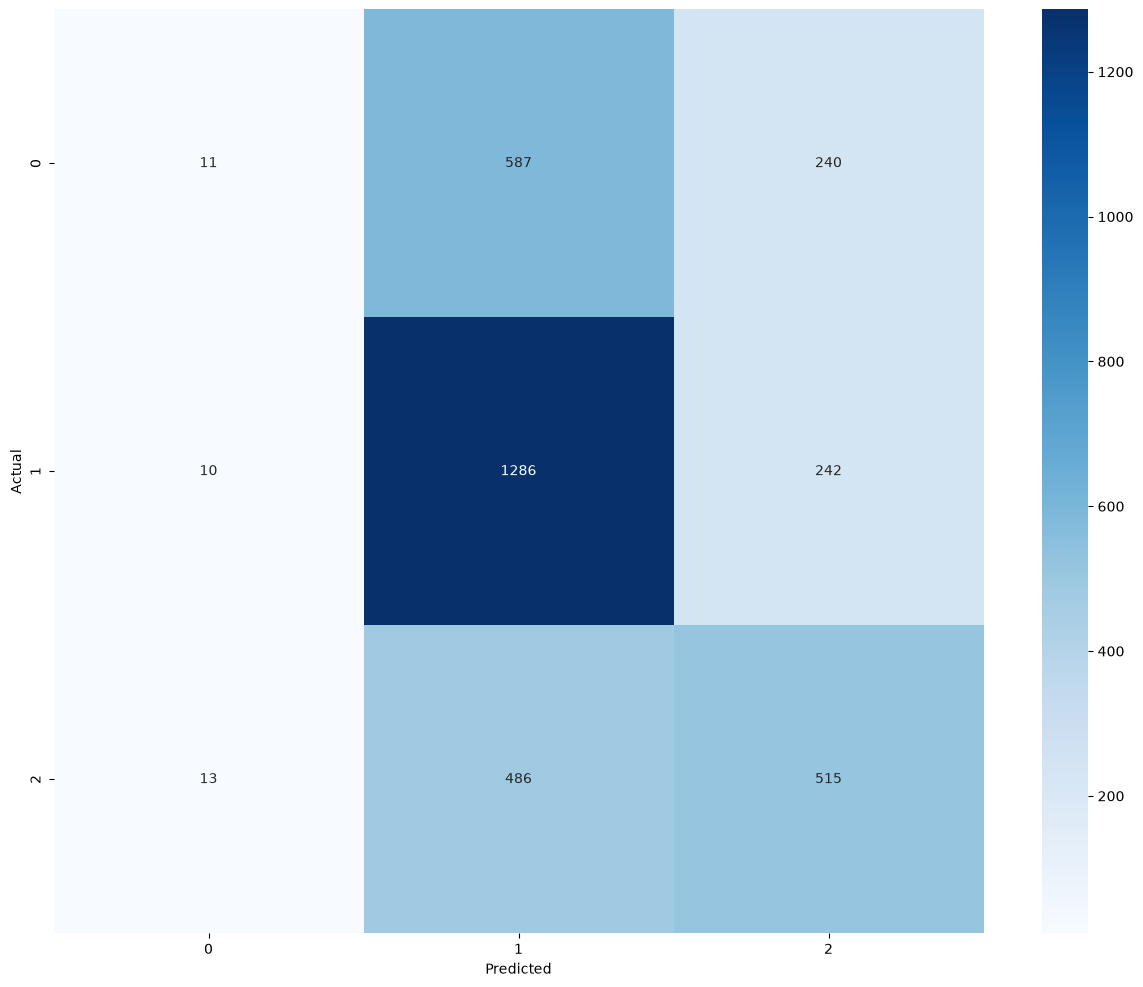

In [67]:
cm = confusion_matrix(y_val ,y_val_pred)
plt.figure(figsize=(15,12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [71]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_Prediction_Phase2")

with mlflow.start_run(run_name="CatBoost_Experiment_1_Baseline"):

    mlflow.log_input(dataset_v2, context="source")

    mlflow.log_params(cbc_model_1.get_params())

    mlflow.log_metrics({
        "train_accuracy": 0.57691,
        "validation_accuracy": 0.53451,
        "validation_macro_precision": 0.46,
        "validation_macro_recall": 0.45,
        "validation_macro_f1": 0.40,
        "draw_recall": 0.01,
        "home_recall": 0.84,
        "away_recall": 0.51,
        "draw_f1": 0.03,
        "home_f1": 0.66,
        "away_f1": 0.51
    })

    mlflow.catboost.log_model(cbc_model_1, "Catboost model 1")

d:\Projects\football-match-outcome-prediction\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/30 15:56:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run CatBoost_Experiment_1_Baseline at: http://127.0.0.1:5000/#/experiments/2/runs/f7b75d876ec048879dc546411419bcbb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


### Experiment 1 — Conclusion

The initial CatBoost model achieved **57.69% training accuracy** and **53.45% validation accuracy**, indicating a moderate difference between training and validation performance.

However, class-specific performance was highly unbalanced:

- **Draw:** 1% recall
- **Home Win:** 84% recall
- **Away Win:** 51% recall

The model achieved a **macro F1-score of 0.40**, with predictions strongly favouring Home Wins and almost completely overlooking Draws.

**Conclusion:** Although CatBoost achieved reasonable overall validation accuracy, its inability to identify Draw outcomes remains a significant limitation. Further experimentation is required to improve balanced recall while maintaining competitive accuracy.

---

## Experiment 2 — CatBoost with Balanced Class Weights

This experiment evaluates CatBoost using auto_class_weights="Balanced" while retaining the same hyperparameters as Experiment 1. The objective is to improve recall across all three outcomes, particularly Draws, without significantly reducing overall accuracy.

In [68]:
cbc_model_2 = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, auto_class_weights="Balanced", random_seed=1, verbose=50)

cbc_model_2.fit(x_train, y_train, cat_features=cat_cols)

0:	learn: 1.0848719	total: 914ms	remaining: 3m 1s
50:	learn: 0.9966057	total: 28.6s	remaining: 1m 23s
100:	learn: 0.9736458	total: 58.1s	remaining: 57s
150:	learn: 0.9373693	total: 1m 28s	remaining: 28.7s
199:	learn: 0.9054199	total: 1m 58s	remaining: 0us


CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=200, learning_rate=0.1, random_seed=1, verbose=50)

In [69]:
y_train_pred = cbc_model_2.predict(x_train).ravel()
y_val_pred = cbc_model_2.predict(x_val).ravel()

print("Train Accuracy:", accuracy_score(y_train, y_train_pred))
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))

print("\nValidation Classification Report:")
print(classification_report(
    y_val, y_val_pred,
    labels=[0, 1, 2],
    target_names=["Draw", "Home", "Away"],
    zero_division=0
))

Train Accuracy: 0.5979009926028956
Validation Accuracy: 0.47227138643067845

Validation Classification Report:
              precision    recall  f1-score   support

        Draw       0.28      0.38      0.32       838
        Home       0.67      0.48      0.56      1538
        Away       0.48      0.54      0.51      1014

    accuracy                           0.47      3390
   macro avg       0.47      0.47      0.46      3390
weighted avg       0.51      0.47      0.48      3390



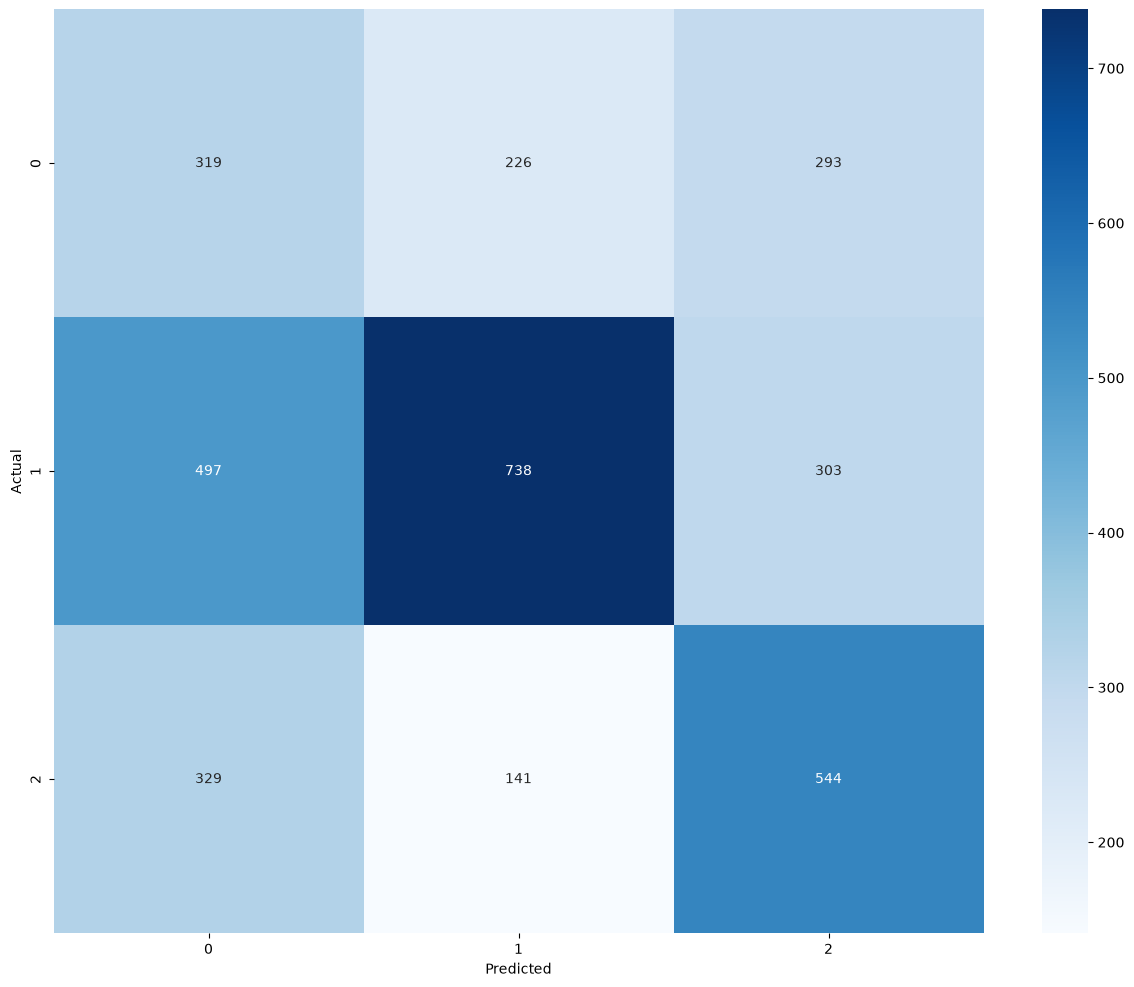

In [72]:
cm = confusion_matrix(y_val ,y_val_pred)
plt.figure(figsize=(15,12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [73]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Football_Prediction_Phase2")

with mlflow.start_run(run_name="CatBoost_Experiment_2"):

    mlflow.log_input(dataset_v2, context="source")

    mlflow.log_params(cbc_model_2.get_params())

    mlflow.log_metrics({
        "train_accuracy": 0.59790,
        "validation_accuracy": 0.47227,
        "validation_macro_precision": 0.47,
        "validation_macro_recall": 0.47,
        "validation_macro_f1": 0.46,
        "draw_recall": 0.38,
        "home_recall": 0.48,
        "away_recall": 0.54,
        "draw_f1": 0.32,
        "home_f1": 0.56,
        "away_f1": 0.51
    })

    mlflow.catboost.log_model(cbc_model_2, "Catboost model 2")

2026/10/30 16:01:41 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run CatBoost_Experiment_2 at: http://127.0.0.1:5000/#/experiments/2/runs/ce29764361f747b0b2a7cb8d30b27561
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


### Experiment 2 — Conclusion

The balanced CatBoost model achieved 59.79% training accuracy and 47.23% validation accuracy, with a macro F1-score of 0.46.

Class-specific recall improved significantly for Draws, increasing from 1% to 38%, while Home recall decreased to 48% and Away recall increased slightly to 54%.

Conclusion: Class balancing improved recall distribution and macro F1, but reduced overall validation accuracy and increased the training-validation gap. Further experimentation is needed to achieve a better balance between predictive accuracy and class-specific recall.

---